# Predicción de aprobación por unidades mediante Red Neuronal Artificial (RNA)

**Curso:** Sistemas Inteligentes (Semana 13)  
**Material de referencia:** `EJEMPLO PERCEPTRON.pdf` y `SESION 12 - SISTEMAS INTELIGENTES.pdf` (Bloques I y II)

## 1. Planteamiento del problema
Se entrena una Red Neuronal Artificial supervisada que prediga si un estudiante **aprobará (1)** o **desaprobará (0)** una experiencia curricular cumpliendo las cuatro reglas del ejercicio:

1. **Tres entradas:** Se evalúan exactamente 3 promedios de unidad (`U1`, `U2`, `U3`).
2. **Condición de aprobación:** El estudiante debe aprobar **al menos 2 de las 3 unidades**.
3. **Sin promedio global:** El estado final no depende del promedio aritmético entre las tres notas, sino únicamente del conteo de unidades aprobadas (por ejemplo, `(20, 13.9, 13.9)` y `(13.8, 13.8, 13.8)` desaprueban; `(14, 14, 2)` y `(13.9, 14, 14)` aprueban).
4. **Rango de notas:** Cada promedio se encuentra en la escala de `0` a `20`.

## 2. Coherencia con el material de clase y regla académica
En la Sesión 12 (Bloque II), el docente implementa redes neuronales multicapa sobre datos tabulares en Python usando **`scikit-learn`** (`MLPClassifier`, `Pipeline`, escalamiento previo, `train_test_split`, `accuracy_score` y `classification_report`), empleando activación `ReLU` en capas ocultas, optimizador `Adam` y salida logística (`Sigmoide`) para clasificación binaria.

De acuerdo con el **reglamento académico de la UNT**:
- **Cada unidad individual requiere `>= 14.0` estricto (`UMBRAL_UNIDAD = 14.0`)**: no existe redondeo por unidad (`13.5`, `13.6` o `13.9` desaprueban la unidad).
- **El medio punto (`13.5`) aplica únicamente al promedio final tradicional** (`UMBRAL_PROMEDIO_REF = 13.5`), usado aquí solo como referencia en la columna comparativa para mostrar la diferencia frente a la regla por unidades.

In [1]:
from itertools import permutations
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import Perceptron
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, StandardScaler

SEMILLA = 42
NOTA_MINIMA = 0.0
NOTA_MAXIMA = 20.0
# Cada unidad aprueba unicamente con >= 14.0 (no hay redondeo por unidad).
UMBRAL_UNIDAD = 14.0
# El 13.5 aplica solo al promedio final referencial para contrastar en tablas.
UMBRAL_PROMEDIO_REF = 13.5

plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["figure.dpi"] = 140
plt.rcParams["axes.edgecolor"] = "#CBD5E1"
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

## 3. Generación balanceada del dataset y casos límite
La función `etiquetar_aprobacion` aplica la regla estricta por unidades (`>= 14.0`) únicamente para generar las etiquetas `y` del conjunto sintético. La RNA nunca recibe esa regla programada en la predicción: debe aprender la frontera desde los datos.

Para que la red defina con precisión el escalón en `14.0`, el dataset combina:
- Muestreo uniforme en `[0, 20]^3`.
- Muestreo denso entre `13.3` y `14.7`, más una banda fina en `[13.5, 14.3]` (`13.5`, `13.8`, `13.9`, `14.0`, `14.1`).
- Casos de contraste donde el promedio final referencial (`>= 13.5`) engaña (por ejemplo, una nota `20` con dos notas en `[13.5, 13.9]`, o dos notas desde `14.0` con una tercera muy baja).

Al final se balancean ambas clases al 50 % para evitar sesgos.

In [2]:
def etiquetar_aprobacion(notas, umbral=UMBRAL_UNIDAD):
    notas_arr = np.asarray(notas, dtype=float)
    unidades_aprobadas = np.sum(notas_arr >= umbral, axis=1)
    return (unidades_aprobadas >= 2).astype(int)


def generar_dataset_balanceado(semilla=SEMILLA, umbral=UMBRAL_UNIDAD):
    rng = np.random.default_rng(semilla)

    # 1. Cobertura general en [0, 20]^3
    muestras_uniformes = np.round(rng.uniform(NOTA_MINIMA, NOTA_MAXIMA, size=(4500, 3)), 1)

    # 2. Densidad simetrica alrededor del corte 13.9 vs 14.0
    banda_umbral = np.round(np.arange(umbral - 0.7, umbral + 0.65, 0.1), 1)
    banda_fina = np.round(np.arange(umbral - 0.5, umbral + 0.45, 0.1), 1)
    muestras_borde = []
    for i in range(7500):
        fila = rng.uniform(NOTA_MINIMA, NOTA_MAXIMA, size=3)
        cantidad_cercanas = rng.choice([1, 2, 3], p=[0.20, 0.45, 0.35])
        origen = banda_fina if i % 2 == 0 else banda_umbral
        for col in rng.choice(3, size=cantidad_cercanas, replace=False):
            fila[col] = rng.choice(origen)
        muestras_borde.append(np.round(fila, 1))
    muestras_borde = np.array(muestras_borde)

    # 3. Casos de contraste entre promedio aritmetico y conteo de unidades (>= 14.0)
    bajas_borde = np.round(np.array([13.5, 13.6, 13.7, 13.8, 13.9]), 1)
    altas_borde = np.round(np.array([14.0, 14.1, 14.2, 14.3, 14.4]), 1)
    muestras_trampa = []
    for i in range(3000):
        if i % 2 == 0:
            u_alta = rng.uniform(16.0, NOTA_MAXIMA)
            if rng.random() < 0.6:
                u_b1, u_b2 = rng.choice(bajas_borde, size=2)
            else:
                u_b1, u_b2 = rng.uniform(NOTA_MINIMA, umbral - 0.1, size=2)
            fila = [u_alta, u_b1, u_b2]
        else:
            u_baja = rng.uniform(NOTA_MINIMA, 8.0)
            if rng.random() < 0.6:
                u_a1, u_a2 = rng.choice(altas_borde, size=2)
            else:
                u_a1, u_a2 = rng.uniform(umbral, 17.5, size=2)
            fila = [u_a1, u_a2, u_baja]
        rng.shuffle(fila)
        muestras_trampa.append(np.round(fila, 1))
    muestras_trampa = np.array(muestras_trampa)

    X_total = np.vstack([muestras_uniformes, muestras_borde, muestras_trampa])
    y_total = etiquetar_aprobacion(X_total, umbral=umbral)

    idx_desaprueba = np.where(y_total == 0)[0]
    idx_aprueba = np.where(y_total == 1)[0]
    n_por_clase = min(len(idx_desaprueba), len(idx_aprueba))

    indices_bal = np.concatenate([
        rng.choice(idx_desaprueba, size=n_por_clase, replace=False),
        rng.choice(idx_aprueba, size=n_por_clase, replace=False),
    ])
    rng.shuffle(indices_bal)

    return X_total[indices_bal], y_total[indices_bal]


X_datos, y_datos = generar_dataset_balanceado()

df_resumen = pd.DataFrame(X_datos, columns=["U1", "U2", "U3"])
df_resumen["Promedio_Referencial"] = df_resumen.mean(axis=1).round(2)
df_resumen["Aprobado"] = y_datos

print(f"Total de registros balanceados: {len(df_resumen)}")
print("Distribución de clases:")
print(df_resumen["Aprobado"].value_counts().rename({0: "Desaprobado (0)", 1: "Aprobado (1)"}))
df_resumen.head(8)

Total de registros balanceados: 11264
Distribución de clases:
Aprobado
Aprobado (1)       5632
Desaprobado (0)    5632
Name: count, dtype: int64


,U1,U2,U3,Promedio_Referencial,Aprobado
0,13.8,14.5,14.1,14.13,1
1,1.0,14.3,14.1,9.80,1
2,13.3,13.9,13.4,13.53,0
3,14.0,13.6,1.4,9.67,0
4,14.3,13.9,18.0,15.40,1
5,4.1,10.4,14.3,9.60,0
6,13.8,13.5,13.3,13.53,0
7,10.1,2.1,3.4,5.20,0


## 4. Escalamiento `[0, 20] -> [0, 1]`, estandarización y limitación del Perceptrón simple
Dividimos los datos de forma estratificada (`80 %` entrenamiento y `20 %` prueba). Primero escalamos cada nota del rango `[0, 20]` a `[0, 1]` dividiendo sobre los límites teóricos `0.0` y `20.0` (`MinMaxScaler`), y después aplicamos `StandardScaler` (como en la Sesión 12) para centrar las entradas alrededor de `0` y facilitar que las unidades `ReLU` posicionen sus cortes exactamente en `14.0`.

Un perceptrón simple traza un único hiperplano lineal $w_1 U_1 + w_2 U_2 + w_3 U_3 + b = 0$, por lo que toda región positiva debería ser convexa. Sin embargo, los puntos `(14, 14, 0)`, `(14, 0, 14)` y `(0, 14, 14)` aprueban (`y = 1`), mientras que su centroide `(9.33, 9.33, 9.33)` tiene cero unidades aprobadas (`y = 0`). Esa falta de convexidad impide que un clasificador lineal resuelva el problema y justifica usar capas ocultas no lineales.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X_datos,
    y_datos,
    test_size=0.20,
    random_state=SEMILLA,
    stratify=y_datos,
)

# 1) Escalamiento fijo [0, 20] -> [0, 1] y 2) centrado con StandardScaler
escalador_01 = MinMaxScaler(feature_range=(0, 1))
escalador_01.fit(np.array([[NOTA_MINIMA, NOTA_MINIMA, NOTA_MINIMA], [NOTA_MAXIMA, NOTA_MAXIMA, NOTA_MAXIMA]]))

estandarizador = StandardScaler()
X_train_norm = estandarizador.fit_transform(escalador_01.transform(X_train))
X_test_norm = estandarizador.transform(escalador_01.transform(X_test))

# Linea base lineal (Perceptron simple) y MLP de 1 capa oculta para comparar capacidad
modelo_perceptron = Perceptron(max_iter=1000, random_state=SEMILLA)
modelo_perceptron.fit(X_train_norm, y_train)
acc_perc_train = accuracy_score(y_train, modelo_perceptron.predict(X_train_norm))
acc_perc_test = accuracy_score(y_test, modelo_perceptron.predict(X_test_norm))

modelo_mlp_1capa = MLPClassifier(
    hidden_layer_sizes=(16,),
    activation="relu",
    solver="adam",
    alpha=1e-6,
    batch_size=64,
    learning_rate_init=0.005,
    max_iter=1200,
    tol=1e-6,
    n_iter_no_change=25,
    random_state=SEMILLA,
)
modelo_mlp_1capa.fit(X_train_norm, y_train)
acc_1c_train = accuracy_score(y_train, modelo_mlp_1capa.predict(X_train_norm))
acc_1c_test = accuracy_score(y_test, modelo_mlp_1capa.predict(X_test_norm))

print(f"Entrenamiento: {X_train.shape[0]} registros | Prueba: {X_test.shape[0]} registros")
print(f"Perceptrón simple -> Train Acc: {acc_perc_train:.4f} | Test Acc: {acc_perc_test:.4f}")
print(f"MLP 1 capa (16)   -> Train Acc: {acc_1c_train:.4f} | Test Acc: {acc_1c_test:.4f}")

Entrenamiento: 9011 registros | Prueba: 2253 registros
Perceptrón simple -> Train Acc: 0.6334 | Test Acc: 0.6201
MLP 1 capa (16)   -> Train Acc: 0.9725 | Test Acc: 0.9694


## 5. Arquitectura final de la RNA (MLP de dos capas ocultas)
La red definitiva mantiene la siguiente estructura:
- **Capa de entrada:** 3 neuronas (`U1`, `U2`, `U3` escaladas y centradas).
- **Capa oculta 1:** 32 neuronas con activación `ReLU` para aproximar cortes individuales por unidad y combinaciones locales.
- **Capa oculta 2:** 16 neuronas con activación `ReLU` para componer las tres regiones ortogonales (regla de al menos 2 de 3 unidades con nota `>= 14.0`).
- **Capa de salida:** 1 neurona con activación logística (`Sigmoide`), entrenada con entropía cruzada binaria (`log_loss`) y optimizador `Adam`.

Se usa `alpha=1e-6` para que la regularización L2 no suavice la transición entre `13.9` y `14.0`.

In [4]:
red_mlp = MLPClassifier(
    hidden_layer_sizes=(32, 16),
    activation="relu",
    solver="adam",
    alpha=1e-6,
    batch_size=64,
    learning_rate_init=0.005,
    max_iter=600,
    tol=1e-6,
    n_iter_no_change=40,
    random_state=SEMILLA,
)

red_mlp.fit(X_train_norm, y_train)
modelo_rna = Pipeline([
    ("escalador_01", escalador_01),
    ("estandarizador", estandarizador),
    ("red", red_mlp),
])

print(f"Épocas ejecutadas hasta convergencia: {red_mlp.n_iter_}")
print(f"Activación de salida: {red_mlp.out_activation_}")
print(f"Pérdida final (Binary Cross-Entropy): {red_mlp.loss_:.5f}")

Épocas ejecutadas hasta convergencia: 280
Activación de salida: logistic
Pérdida final (Binary Cross-Entropy): 0.00011


## 6. Métricas de evaluación, curvas y frontera de decisión
Evaluamos `modelo_rna` sobre el conjunto de prueba (`X_test`) y verificamos todas las `9,261` combinaciones enteras posibles de `(U1, U2, U3)` entre `0` y `20` (`13` desaprueba y `14` aprueba).

In [5]:
y_pred_train = modelo_rna.predict(X_train)
y_pred_test = modelo_rna.predict(X_test)
y_prob_test = modelo_rna.predict_proba(X_test)[:, 1]

acc_train = accuracy_score(y_train, y_pred_train)
acc_test = accuracy_score(y_test, y_pred_test)
roc_auc_test = roc_auc_score(y_test, y_prob_test)
matriz_conf = confusion_matrix(y_test, y_pred_test)

print(f"Accuracy entrenamiento (MLP 32-16): {acc_train:.4f}")
print(f"Accuracy prueba        (MLP 32-16): {acc_test:.4f}")
print(f"ROC-AUC prueba         (MLP 32-16): {roc_auc_test:.4f}\n")
print("Reporte de clasificación:")
print(classification_report(y_test, y_pred_test, target_names=["Desaprobado (0)", "Aprobado (1)"]))

# Barrido exhaustivo de las 21^3 = 9261 combinaciones enteras en [0..20]^3
rejilla_enteros = np.array(
    np.meshgrid(np.arange(21), np.arange(21), np.arange(21))
).T.reshape(-1, 3)
y_enteros_real = etiquetar_aprobacion(rejilla_enteros)
y_enteros_pred = modelo_rna.predict(rejilla_enteros)
acc_enteros = accuracy_score(y_enteros_real, y_enteros_pred)
errores_enteros = int(np.sum(y_enteros_real != y_enteros_pred))
print(f"Exactitud en las 9,261 combinaciones enteras [0..20]^3: {acc_enteros:.4f} (errores={errores_enteros})")

Accuracy entrenamiento (MLP 32-16): 1.0000
Accuracy prueba        (MLP 32-16): 1.0000
ROC-AUC prueba         (MLP 32-16): 1.0000

Reporte de clasificación:
                 precision    recall  f1-score   support

Desaprobado (0)       1.00      1.00      1.00      1127
   Aprobado (1)       1.00      1.00      1.00      1126

       accuracy                           1.00      2253
      macro avg       1.00      1.00      1.00      2253
   weighted avg       1.00      1.00      1.00      2253

Exactitud en las 9,261 combinaciones enteras [0..20]^3: 1.0000 (errores=0)


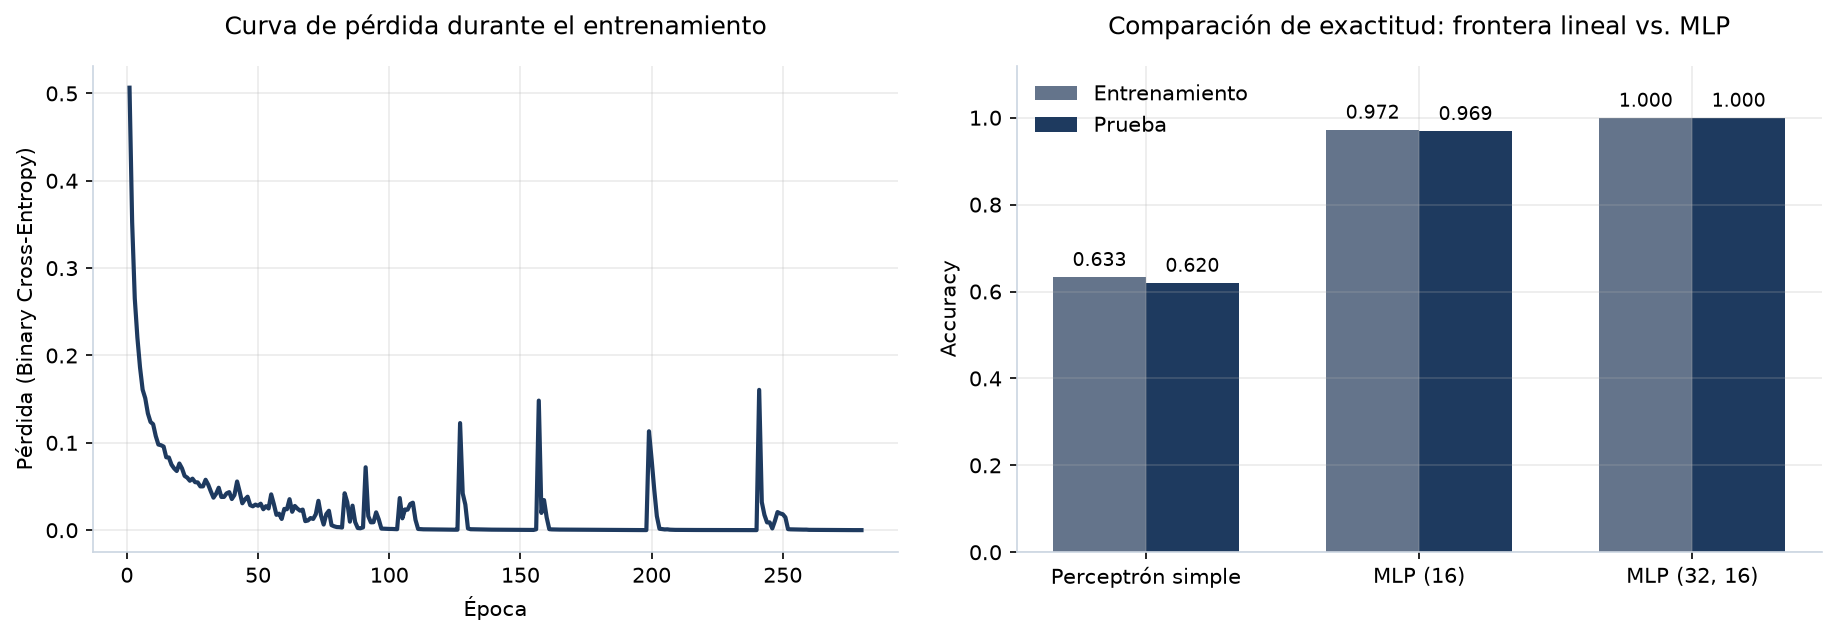

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12.6, 4.6), dpi=150)

epocas = np.arange(1, len(red_mlp.loss_curve_) + 1)
axes[0].plot(epocas, red_mlp.loss_curve_, color="#1E3A5F", linewidth=2)
axes[0].set_title("Curva de pérdida durante el entrenamiento", pad=15)
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Pérdida (Binary Cross-Entropy)")
sns.despine(ax=axes[0])

modelos_comp = ["Perceptrón simple", "MLP (16)", "MLP (32, 16)"]
accs_train = [acc_perc_train, acc_1c_train, acc_train]
accs_test = [acc_perc_test, acc_1c_test, acc_test]
pos = np.arange(len(modelos_comp))
ancho = 0.34

b1 = axes[1].bar(pos - ancho / 2, accs_train, width=ancho, color="#64748B", label="Entrenamiento")
b2 = axes[1].bar(pos + ancho / 2, accs_test, width=ancho, color="#1E3A5F", label="Prueba")
axes[1].set_xticks(pos)
axes[1].set_xticklabels(modelos_comp)
axes[1].set_ylim(0.0, 1.12)
axes[1].set_ylabel("Accuracy")
axes[1].set_title("Comparación de exactitud: frontera lineal vs. MLP", pad=15)
axes[1].legend(frameon=False)
sns.despine(ax=axes[1])

for barra in list(b1) + list(b2):
    altura = barra.get_height()
    axes[1].text(barra.get_x() + barra.get_width() / 2, altura + 0.015, f"{altura:.3f}", ha="center", va="bottom", fontsize=9)

fig.tight_layout(pad=2.0)
plt.show()

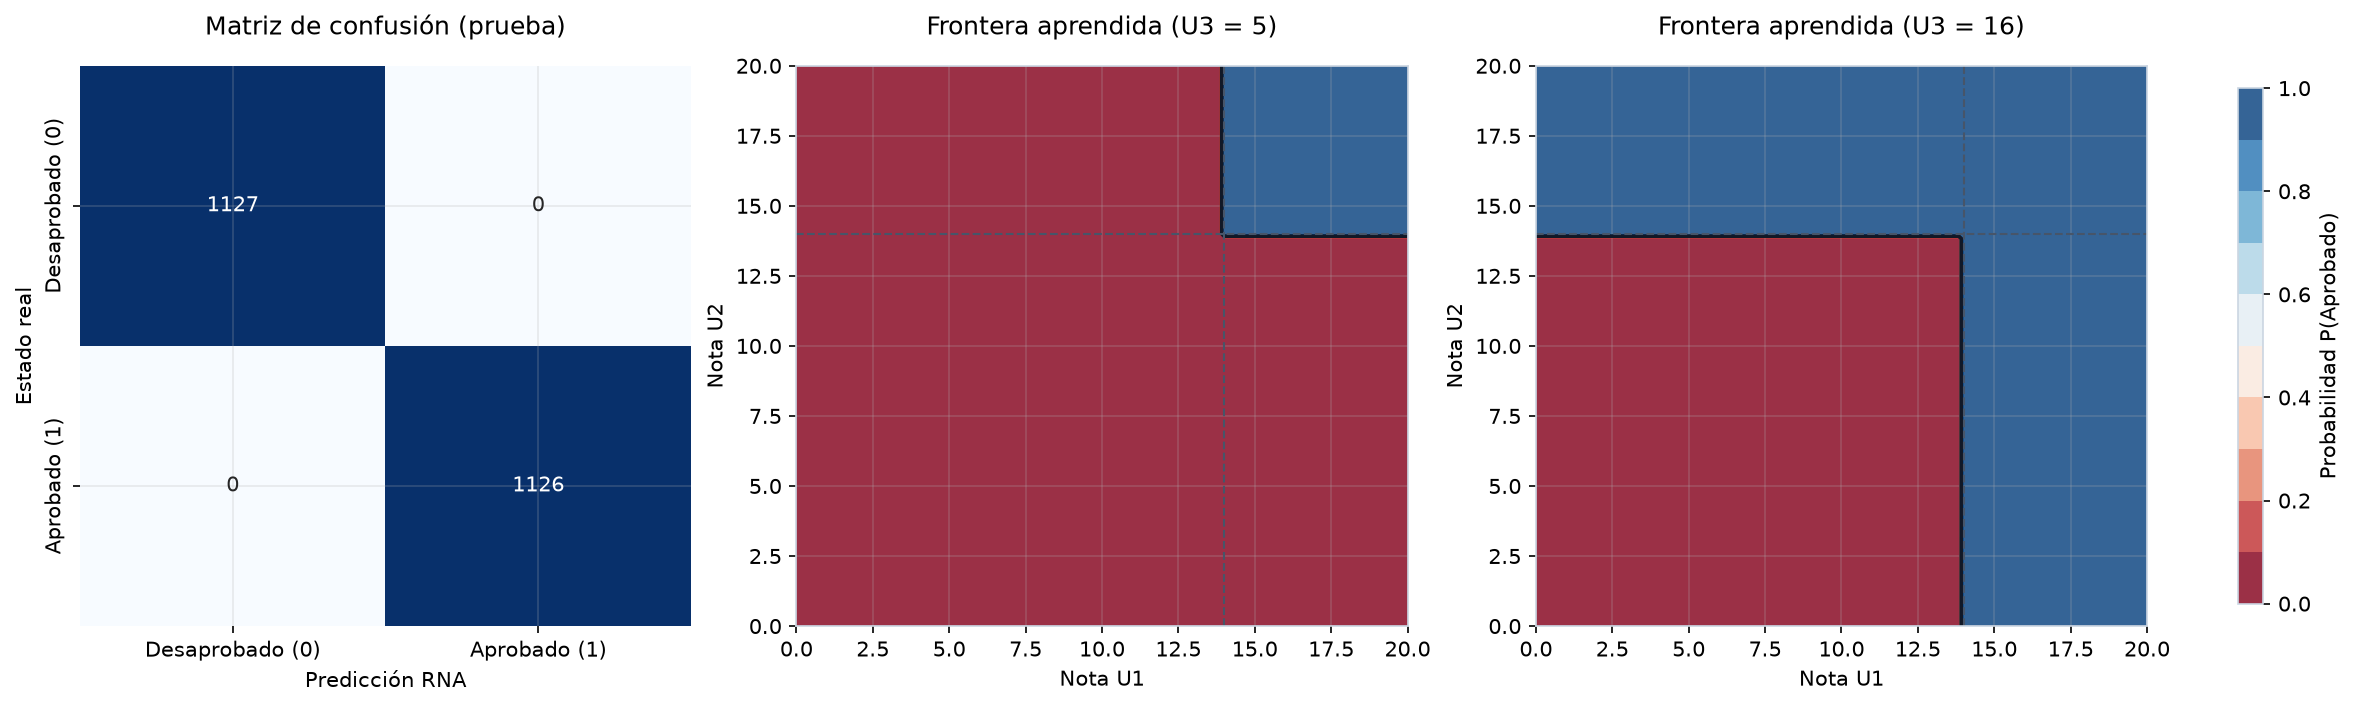

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15.6, 4.6), dpi=150, layout="constrained")

sns.heatmap(
    matriz_conf,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["Desaprobado (0)", "Aprobado (1)"],
    yticklabels=["Desaprobado (0)", "Aprobado (1)"],
    ax=axes[0],
)
axes[0].set_title("Matriz de confusión (prueba)", pad=15)
axes[0].set_xlabel("Predicción RNA")
axes[0].set_ylabel("Estado real")

# Cortes 2D de la frontera aprendida fijando U3 en 5.0 (desaprobada) y en 16.0 (aprobada)
eje = np.linspace(0, 20, 121)
g1, g2 = np.meshgrid(eje, eje)

for idx, u3_fija in enumerate([5.0, 16.0], start=1):
    malla = np.column_stack([g1.ravel(), g2.ravel(), np.full(g1.size, u3_fija)])
    prob_malla = modelo_rna.predict_proba(malla)[:, 1].reshape(g1.shape)
    cont = axes[idx].contourf(g1, g2, prob_malla, levels=np.linspace(0, 1, 11), cmap="RdBu", alpha=0.85)
    axes[idx].contour(g1, g2, prob_malla, levels=[0.5], colors=["#111827"], linewidths=1.8)
    axes[idx].axvline(UMBRAL_UNIDAD, color="#475569", linestyle="--", linewidth=1)
    axes[idx].axhline(UMBRAL_UNIDAD, color="#475569", linestyle="--", linewidth=1)
    axes[idx].set_title(f"Frontera aprendida (U3 = {u3_fija:.0f})", pad=15)
    axes[idx].set_xlabel("Nota U1")
    axes[idx].set_ylabel("Nota U2")

fig.colorbar(cont, ax=axes[1:], shrink=0.92, label="Probabilidad P(Aprobado)")
plt.show()

En los dos cortes 2D se comprueba la frontera no lineal aprendida en torno a `14.0`: cuando `U3 = 5` (desaprobada), solo aprueba el cuadrante `U1 >= 14.0` y `U2 >= 14.0`; cuando `U3 = 16` (aprobada), basta aprobar `U1` o `U2` (región en L).

## 7. Pruebas con casos trampa y casos límite
Comprobamos la predicción de la RNA sobre casos donde el promedio final referencial (`>= 13.5`) falla y en valores cercanos al umbral estricto por unidad (`13.5`, `13.8`, `13.9`, `14.0`, `14.1`), junto con todas sus permutaciones.

In [8]:
casos_base = [
    (13.5, 13.5, 5.0),
    (13.8, 13.8, 13.8),
    (13.9, 13.9, 13.9),
    (20.0, 12.0, 12.0),
    (20.0, 13.5, 13.5),
    (20.0, 13.8, 13.8),
    (20.0, 13.9, 13.9),
    (14.0, 14.0, 2.0),
    (14.0, 14.0, 0.0),
    (14.1, 14.1, 4.0),
    (13.9, 14.0, 14.0),
    (13.9, 13.9, 14.0),
    (9.3, 9.3, 9.3),
]

filas_prueba = []
for u1, u2, u3 in casos_base:
    entrada = np.array([[u1, u2, u3]])
    estado_real = int(etiquetar_aprobacion(entrada)[0])
    pred_rna = int(modelo_rna.predict(entrada)[0])
    prob_rna = float(modelo_rna.predict_proba(entrada)[0, 1])
    promedio = float(np.mean(entrada))
    criterio_prom = 1 if promedio >= UMBRAL_PROMEDIO_REF else 0
    filas_prueba.append({
        "U1": u1,
        "U2": u2,
        "U3": u3,
        "Promedio_Simple": round(promedio, 2),
        "Diria_Promedio": "Aprueba" if criterio_prom == 1 else "Desaprueba",
        "Estado_Real": "Aprueba" if estado_real == 1 else "Desaprueba",
        "Prob_RNA": round(prob_rna, 4),
        "Prediccion_RNA": "Aprueba" if pred_rna == 1 else "Desaprueba",
        "Acierto_RNA": pred_rna == estado_real,
    })

df_casos = pd.DataFrame(filas_prueba)
aciertos_base = int(df_casos["Acierto_RNA"].sum())

todas_permutaciones = sorted({perm for c in casos_base for perm in permutations(c)})
X_perm = np.array(todas_permutaciones)
aciertos_perm = int(np.sum(modelo_rna.predict(X_perm) == etiquetar_aprobacion(X_perm)))

print(f"Aciertos en casos trampa base: {aciertos_base}/{len(df_casos)}")
print(f"Aciertos en todas sus permutaciones ({len(X_perm)} casos): {aciertos_perm}/{len(X_perm)}")
df_casos

Aciertos en casos trampa base: 13/13
Aciertos en todas sus permutaciones (33 casos): 33/33


,U1,U2,U3,Promedio_Simple,Diria_Promedio,Estado_Real,Prob_RNA,Prediccion_RNA,Acierto_RNA
0,13.5,13.5,5.0,10.67,Desaprueba,Desaprueba,0.0000,Desaprueba,True
1,13.8,13.8,13.8,13.80,Aprueba,Desaprueba,0.0000,Desaprueba,True
2,13.9,13.9,13.9,13.90,Aprueba,Desaprueba,0.0000,Desaprueba,True
3,20.0,12.0,12.0,14.67,Aprueba,Desaprueba,0.0000,Desaprueba,True
4,20.0,13.5,13.5,15.67,Aprueba,Desaprueba,0.0000,Desaprueba,True
5,20.0,13.8,13.8,15.87,Aprueba,Desaprueba,0.0004,Desaprueba,True
6,20.0,13.9,13.9,15.93,Aprueba,Desaprueba,0.0031,Desaprueba,True
7,14.0,14.0,2.0,10.00,Desaprueba,Aprueba,0.9997,Aprueba,True
8,14.0,14.0,0.0,9.33,Desaprueba,Aprueba,0.9994,Aprueba,True
9,14.1,14.1,4.0,10.73,Desaprueba,Aprueba,1.0000,Aprueba,True


## 8. Exportación del modelo entrenado
Guardamos el `Pipeline` entrenado junto con el umbral estricto por unidad (`14.0`), la referencia de promedio final (`13.5`), las curvas de entrenamiento y las métricas de prueba en `modelo_rna_aprobacion.pkl` para cargarlo directamente desde `app.py` sin reentrenar.

In [9]:
metricas_reporte = classification_report(
    y_test,
    y_pred_test,
    target_names=["Desaprobado (0)", "Aprobado (1)"],
    output_dict=True,
)

paquete_modelo = {
    "modelo": modelo_rna,
    "umbral_unidad": UMBRAL_UNIDAD,
    "umbral_promedio_ref": UMBRAL_PROMEDIO_REF,
    "nota_minima": NOTA_MINIMA,
    "nota_maxima": NOTA_MAXIMA,
    "arquitectura": "3 -> 32 (ReLU) -> 16 (ReLU) -> 1 (Sigmoide)",
    "epocas": int(red_mlp.n_iter_),
    "loss_curve": [float(v) for v in red_mlp.loss_curve_],
    "comparacion_modelos": {
        "Perceptrón simple": {"train": float(acc_perc_train), "test": float(acc_perc_test)},
        "MLP (16)": {"train": float(acc_1c_train), "test": float(acc_1c_test)},
        "MLP (32, 16)": {"train": float(acc_train), "test": float(acc_test)},
    },
    "metricas": {
        "accuracy_entrenamiento": float(acc_train),
        "accuracy_prueba": float(acc_test),
        "roc_auc_prueba": float(roc_auc_test),
        "accuracy_enteros": float(acc_enteros),
        "errores_enteros": errores_enteros,
        "total_entrenamiento": int(len(X_train)),
        "total_prueba": int(len(X_test)),
        "matriz_confusion": matriz_conf.tolist(),
        "reporte_clasificacion": metricas_reporte,
        "aciertos_permutaciones": aciertos_perm,
        "total_permutaciones": int(len(X_perm)),
    },
}

ruta_salida = Path("modelo_rna_aprobacion.pkl")
joblib.dump(paquete_modelo, ruta_salida)
print(f"Modelo guardado correctamente en: {ruta_salida.resolve()}")

Modelo guardado correctamente en: C:\k3vindo04\UNIVERSIDAD\VI CICLO\SISTEMAS INTELIGENTES\Semana 13\Ejercicio_RNA_Unidades\modelo_rna_aprobacion.pkl
